<a href="https://colab.research.google.com/github/tejas883/Roll_No_32_Machine-Learning-Lab/blob/main/ML_Experiment_9_Classification_and_Regression_Trees_(CART).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  ML Experiment Number 9

Student Name : Tejas Surendra Mule


Batch : CS 02


Roll Number : CS32



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


df = pd.read_csv("palmerpenguins_extended.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3430, 11)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
print("Missing values:", int(df.isnull().sum().sum()))
df = df.dropna()   # drop rows with missing values (none here)

# In this file culmen_* columns are named bill_*
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = df[features]

le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = le.classes_

print("Feature matrix shape:", X.shape)
print("Classes:", dict(zip(range(len(class_names)), class_names)))

Missing values: 0
Feature matrix shape: (3430, 4)
Classes: {0: 'Adelie', 1: 'Chinstrap', 2: 'Gentoo'}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 2744
Testing samples : 686


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# max_depth=3 limits overfitting (an unrestricted tree memorizes the training data)
cart = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
cart.fit(X_train, y_train)
y_pred_cart = cart.predict(X_test)
print("CART model trained successfully.")

CART model trained successfully.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

Accuracy: 0.5641


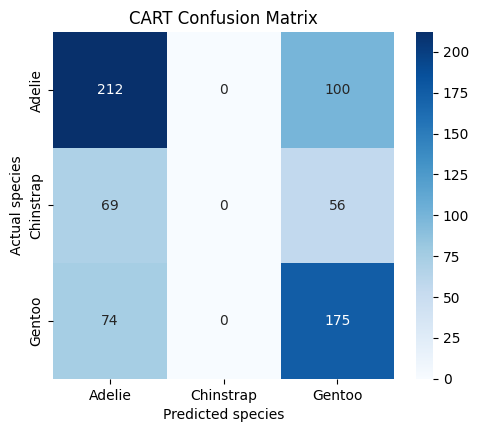

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.60      0.68      0.64       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.53      0.70      0.60       249

    accuracy                           0.56       686
   macro avg       0.38      0.46      0.41       686
weighted avg       0.46      0.56      0.51       686



In [ ]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_cart):.4f}")

cm = confusion_matrix(y_test, y_pred_cart)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("CART Confusion Matrix")
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred_cart, target_names=class_names, zero_division=0))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


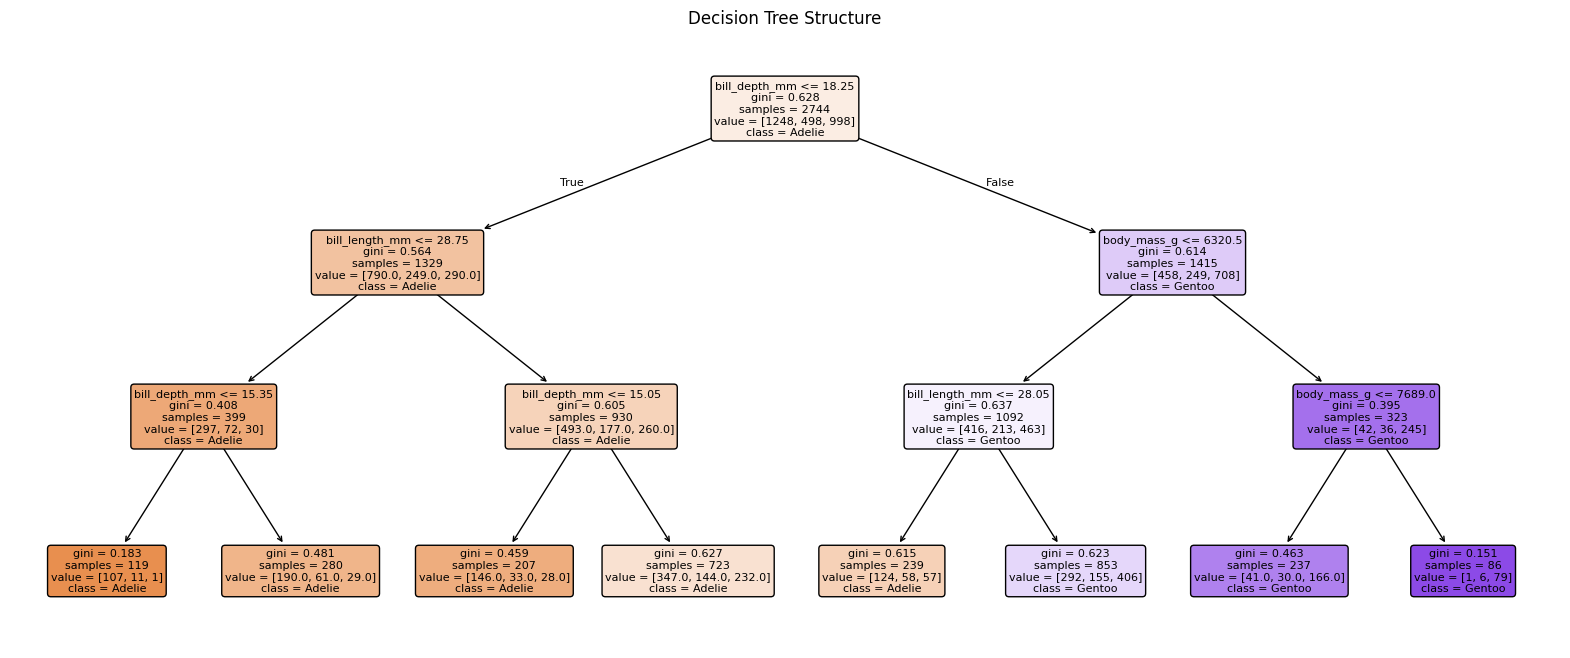

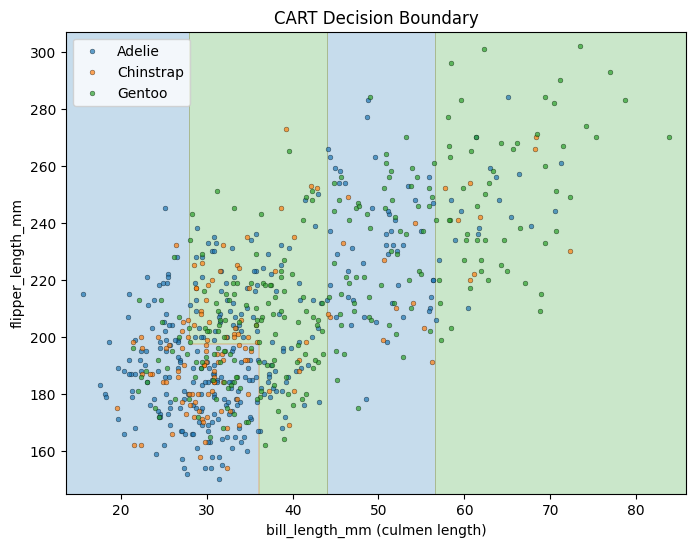

In [ ]:
# Tree structure
plt.figure(figsize=(20, 8))
plot_tree(cart, feature_names=features, class_names=list(class_names), filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree Structure")
plt.show()

# 2-D model: bill (culmen) length and flipper length
feat2 = ["bill_length_mm", "flipper_length_mm"]
X2_train, X2_test = X_train[feat2], X_test[feat2]

cart2 = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
cart2.fit(X2_train, y_train)

colors = ["tab:blue", "tab:orange", "tab:green"]

def plot_boundary(model, X2, y_true, ax, title):
    x_min, x_max = X2.iloc[:, 0].min() - 2, X2.iloc[:, 0].max() + 2
    y_min, y_max = X2.iloc[:, 1].min() - 5, X2.iloc[:, 1].max() + 5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X2.columns)
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(len(class_names) + 1) - 0.5, colors=colors, alpha=0.25)
    for k, name in enumerate(class_names):
        m = y_true == k
        ax.scatter(X2.iloc[m, 0], X2.iloc[m, 1], s=12, color=colors[k],
                   edgecolor="k", linewidths=0.3, alpha=0.7, label=name)
    ax.set_xlabel("bill_length_mm (culmen length)")
    ax.set_ylabel("flipper_length_mm")
    ax.set_title(title)
    ax.legend(loc="upper left")

fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(cart2, X2_test, y_test, ax, "CART Decision Boundary")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

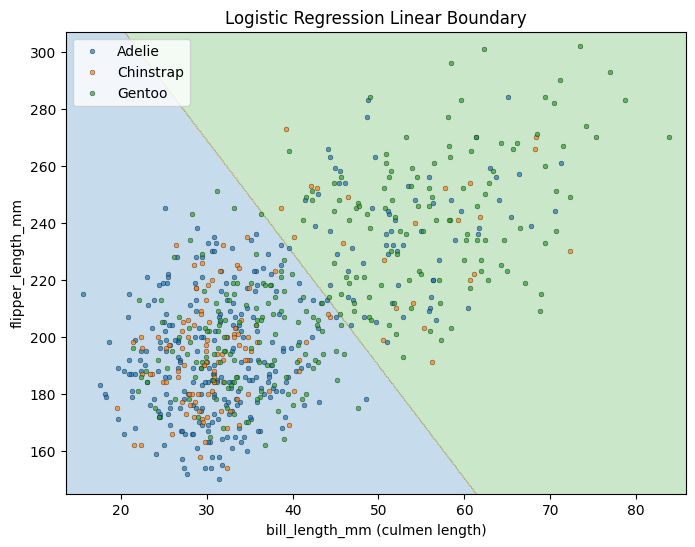

In [ ]:
lr2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr2.fit(X2_train, y_train)

fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(lr2, X2_test, y_test, ax, "Logistic Regression Linear Boundary")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

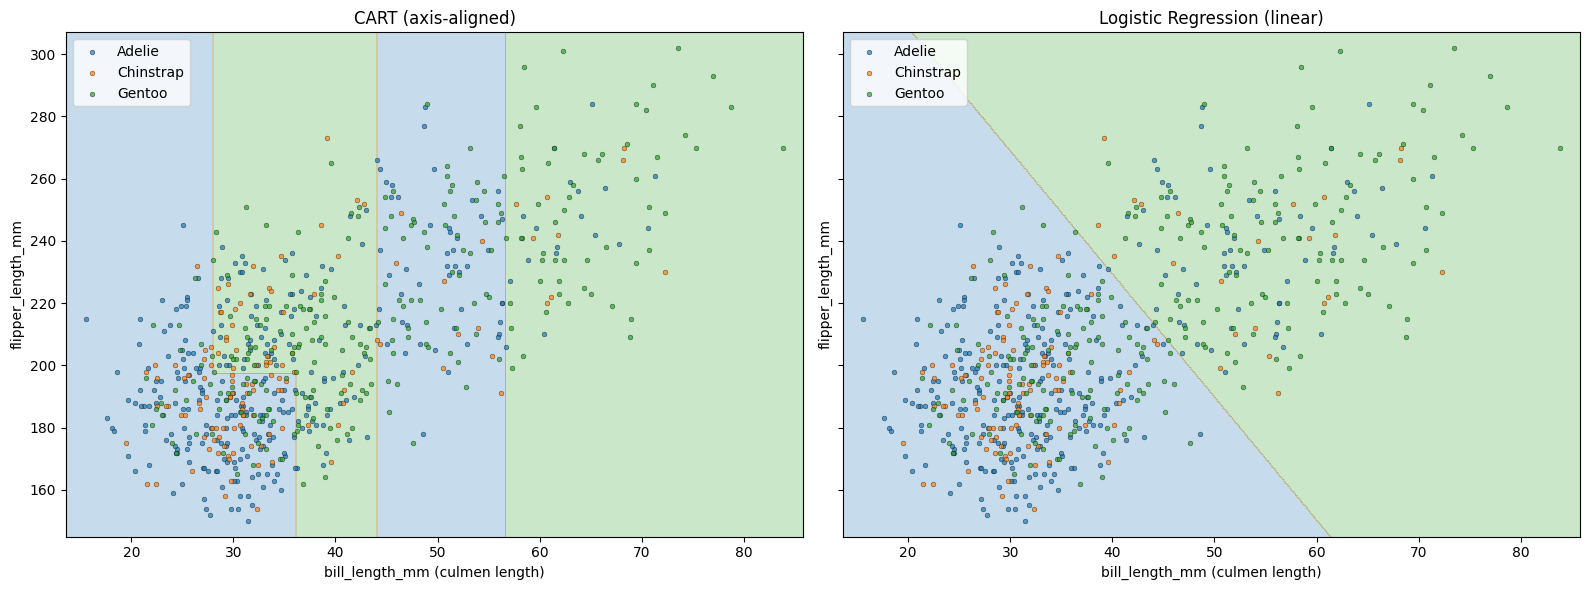

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
plot_boundary(cart2, X2_test, y_test, axes[0], "CART (axis-aligned)")
plot_boundary(lr2, X2_test, y_test, axes[1], "Logistic Regression (linear)")
plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART accuracy                : 0.4927
Logistic Regression accuracy : 0.5262


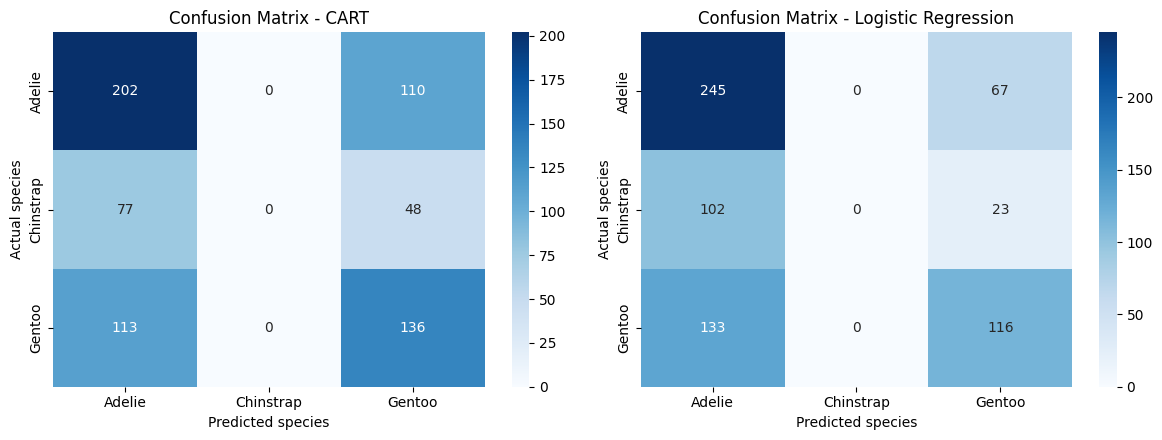

Classification Report - CART
              precision    recall  f1-score   support

      Adelie       0.52      0.65      0.57       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.46      0.55      0.50       249

    accuracy                           0.49       686
   macro avg       0.33      0.40      0.36       686
weighted avg       0.40      0.49      0.44       686

Classification Report - Logistic Regression
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686



In [ ]:
y_pred_cart2 = cart2.predict(X2_test)
y_pred_lr2 = lr2.predict(X2_test)

print(f"CART accuracy                : {accuracy_score(y_test, y_pred_cart2):.4f}")
print(f"Logistic Regression accuracy : {accuracy_score(y_test, y_pred_lr2):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, title in [(axes[0], y_pred_cart2, "CART"), (axes[1], y_pred_lr2, "Logistic Regression")]:
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")
    ax.set_title("Confusion Matrix - " + title)
plt.tight_layout()
plt.show()

print("Classification Report - CART")
print(classification_report(y_test, y_pred_cart2, target_names=class_names, zero_division=0))
print("Classification Report - Logistic Regression")
print(classification_report(y_test, y_pred_lr2, target_names=class_names, zero_division=0))

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.